# Laboratorium: Adaline i spadek gradientu

**Podstawy AI**

Na poprzednich zajęciach perceptron uczył się na pomyłkach: błąd $y - \hat y$ miał tylko wartości $0, \pm 1$. Dziś zbudujesz **Adaline** (Widrow i Hoff, 1960): neuron, który wie, *jak bardzo* się myli, i uczy się, minimalizując **funkcję straty** metodą **spadku gradientu**.

Plan:
1. spadek gradientu na jednej wadze (kartka 1 w kodzie),
2. implementacja Adaline,
3. Adaline na danych Iris: za duże i za małe $\eta$, granica stabilności,
4. mapa $\eta$ × epoki: kiedy więcej epok pomaga,
5. granica decyzyjna w czasie: co się dzieje, gdy trafność jest już 100%.

Dziś skupiamy się na zrozumieniu, jak $\eta$ i liczba epok wpływają na uczenie. Standaryzację i stochastyczny spadek gradientu poznamy na następnych zajęciach.

**Jak pracujemy:** komórki oznaczone `# TODO` uzupełniasz sam. W eksperymentach stosujemy zasadę **przewiduję → uruchamiam → wyjaśniam**.

**Na koniec:** wrzuć uzupełniony notebook na swojego GitHuba.

Notebook wzoruje się na rozdziale 2 książki S. Raschki *Machine Learning with PyTorch and Scikit-Learn*.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris

np.set_printoptions(precision=4, suppress=True)

## 1. Spadek gradientu na jednej wadze

Na kartce 1 liczyłeś ręcznie kroki spadku gradientu dla

$$L(w) = (w - 3)^2, \qquad w_{k+1} = w_k - \eta \cdot 2(w_k - 3), \qquad w_0 = 0.$$

Teraz to samo w kodzie, dla wielu kroków i wielu wartości $\eta$.

### Zadanie 1
Uzupełnij funkcję `spadek_1d`: w pętli policz kolejne $w_{k+1}$ z $w_k$ i dopisz do listy. Funkcja zwraca listę $[w_0, w_1, \dots, w_n]$.

In [2]:
def spadek_1d(eta, w0=0.0, n_krokow=10):
    w = w0
    trajektoria = [w]
    for k in range(n_krokow):
        # TODO: jeden krok spadku gradientu dla L(w) = (w - 3)^2
        w = trajektoria[k] - eta * 2 * (trajektoria[k] - 3)
        trajektoria.append(w)
    return trajektoria

In [3]:
# Sprawdzenie z kartką 1: pierwsze trzy kroki
for eta in [0.25, 1.0, 1.1]:
    print(f"η = {eta:<5}", [round(w, 4) for w in spadek_1d(eta, n_krokow=3)])

η = 0.25  [0.0, 1.5, 2.25, 2.625]
η = 1.0   [0.0, 6.0, 0.0, 6.0]
η = 1.1   [0.0, 6.6, -1.32, 8.184]


Powinieneś zobaczyć dokładnie to, co na kartce: $[0, 1.5, 2.25, 2.625]$, $[0, 6, 0, 6]$ i $[0, 6.6, -1.32, 8.184]$.

Teraz narysujmy trajektorie dla większej liczby $\eta$, po 10 kroków.

**Przewiduję:** przy którym $\eta$ z listy $\{0.1,\ 0.25,\ 0.5,\ 0.9,\ 1.0,\ 1.1\}$ dojdziemy do minimum najszybciej?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):** Przewiduję, że dla eta = 1.1. Różnice są najbardziej drastyczne.

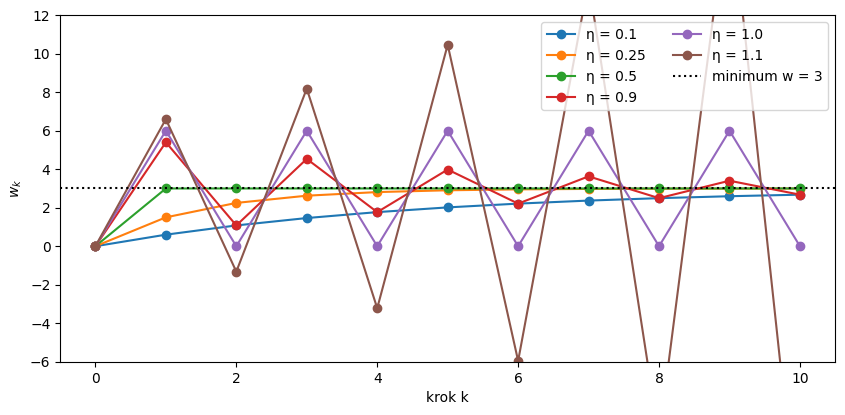

η = 0.1   w_10 =     2.6779
η = 0.25  w_10 =     2.9971
η = 0.5   w_10 =     3.0000
η = 0.9   w_10 =     2.6779
η = 1.0   w_10 =     0.0000
η = 1.1   w_10 =   -15.5752


In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for eta in [0.1, 0.25, 0.5, 0.9, 1.0, 1.1]:
    ax.plot(range(11), spadek_1d(eta), marker="o", label=f"η = {eta}")
ax.axhline(3, color="k", ls=":", label="minimum w = 3")
ax.set_xlabel("krok k"); ax.set_ylabel("$w_k$"); ax.set_ylim(-6, 12)
ax.legend(ncol=2); plt.show()

for eta in [0.1, 0.25, 0.5, 0.9, 1.0, 1.1]:
    print(f"η = {eta:<4}  w_10 = {spadek_1d(eta)[-1]:10.4f}")

**Pytanie 1.** (a) Przy którym $\eta$ dochodzimy do minimum w **jednym** kroku? (b) Dlaczego przy $\eta = 0.9$ waga skacze na boki, a mimo to zbiega? (c) Gdzie jest granica między zbieżnością a rozbieżnością?

Wskazówka: przekształć wzór na krok do postaci $w_{k+1} - 3 = c \cdot (w_k - 3)$. Ile wynosi $c$?

✍️ **Twoja odpowiedź:**

(a) Do minimum w jednym kroku dochodzimy przy $\eta = 0.5$.

(b) Przy $\eta = 0.9$ waga skacze na boki, ponieważ wartość współczynnika $c = 1 - 2\eta$ jest ujemna (c = 1 - 1.8 = -0.8), co powoduje zmianę znaku błędu w każdym kroku. Mimo to proces zbiega, ponieważ wartość bezwzględna $|c| = 0.8$ jest mniejsza od 1, więc z każdym krokiem odległość od minimum się zmniejsza.

(c) Granica między zbieżnością a rozbieżnością leży w punkcie $\eta = 1.0$ (gdzie $|c| = 1$):
* Dla $\eta < 1.0$ mamy $|c| < 1$, co oznacza zbieżność do minimum.
* Dla $\eta = 1.0$ mamy $c = -1$, co powoduje ciągłe oscylacje o stałej amplitudzie (brak zbieżności i rozbieżności).
* Dla $\eta > 1.0$ mamy $|c| > 1$, co prowadzi do rozbieżności (wartości oddalają się od minimum do nieskończoności).

$$w_{k+1} = w_k - \eta \cdot 2(w_k - 3)$$

$$w_{k+1} - 3 = w_k - 3 - 2\eta(w_k - 3)$$

$$w_{k+1} - 3 = (1 - 2\eta) \cdot (w_k - 3)$$

Stąd:
$$c = 1 - 2\eta$$

## 2. Adaline — przypomnienie

Neuron liczy, tak jak perceptron, **pobudzenie** $z = \mathbf{w}^T\mathbf{x} + b$. Różnica jest w uczeniu:

| | perceptron | Adaline |
|---|---|---|
| błąd | $y - \hat{y}$, tylko $0, \pm 1$ | $y - z$, dowolna liczba |
| poprawka | po każdym przykładzie | raz na epokę, z całego zbioru |
| predykcja | $\hat y = 1$, gdy $z \ge 0$ | $\hat y = 1$, gdy $z \ge 0.5$ |

**Funkcja straty** (średni błąd kwadratowy, MSE) mówi jedną liczbą, jak źle jest:

$$L(\mathbf{w}, b) = \frac{1}{n}\sum_{i=1}^{n}\left(y^{(i)} - z^{(i)}\right)^2$$

**Spadek gradientu.** Pochodne straty po wagach i biasie (wyprowadzenie na slajdach):

$$\frac{\partial L}{\partial w_j} = -\frac{2}{n}\sum_i \left(y^{(i)} - z^{(i)}\right) x_j^{(i)}, \qquad \frac{\partial L}{\partial b} = -\frac{2}{n}\sum_i \left(y^{(i)} - z^{(i)}\right)$$

Robimy krok w stronę przeciwną do gradientu:

$$w_j := w_j + \eta \cdot \frac{2}{n}\sum_i \left(y^{(i)} - z^{(i)}\right) x_j^{(i)}, \qquad b := b + \eta \cdot \frac{2}{n}\sum_i \left(y^{(i)} - z^{(i)}\right)$$

### Zadanie 2 — uzupełnij metodę `fit`

Brakuje **czterech linijek** w pętli uczącej:
1. `errors` — wektor błędów $y - z$ dla **wszystkich** przykładów naraz (`output` jest już policzone),
2. aktualizacja wag `self.w_`,
3. aktualizacja biasu `self.b_`,
4. `loss` — średni błąd kwadratowy w tej epoce.

Wskazówki:
- sumę $\sum_i e^{(i)} x_j^{(i)}$ dla wszystkich $j$ naraz liczy `X.T @ errors`,
- $n$ to `X.shape[0]`,
- średnią liczy `.mean()`, kwadrat `** 2`.

Parametr `verbose=True` wypisuje stan po każdej epoce, tak jak liczyłeś na kartce.

In [5]:
class AdalineGD:
    """ADAptive LInear NEuron, uczony pełnym spadkiem gradientu (etykiety 0/1).

    Parametry
    ---------
    eta : float        współczynnik uczenia
    n_iter : int       liczba epok
    w_init : str       'random' (małe losowe, jak u Raschki) albo 'zeros'
    random_state : int ziarno generatora liczb losowych
    verbose : bool     czy wypisywać stan po każdej epoce

    Atrybuty po uczeniu
    -------------------
    w_ : wagi,  b_ : bias,  losses_ : wartość MSE w każdej epoce
    """

    def __init__(self, eta=0.01, n_iter=50, w_init="random", random_state=1, verbose=False):
        self.eta = eta
        self.n_iter = n_iter
        self.w_init = w_init
        self.random_state = random_state
        self.verbose = verbose

    def fit(self, X, y):
        if self.w_init == "zeros":
            self.w_ = np.zeros(X.shape[1])
        else:
            rgen = np.random.RandomState(self.random_state)
            self.w_ = rgen.normal(loc=0.0, scale=0.01, size=X.shape[1])
        self.b_ = 0.0
        self.losses_ = []

        for epoka in range(1, self.n_iter + 1):
            net_input = self.net_input(X)          # z dla WSZYSTKICH przykładów naraz
            output = self.activation(net_input)    # Adaline: aktywacja liniowa, output = z
            # TODO
            errors = y - output                    # y − z
            self.w_ += self.eta * 2.0 / X.shape[0] * X.T @ errors        # η · 2/n · X.T @ errors
            self.b_ += self.eta * 2.0 * errors.mean()                   # η · 2/n · suma błędów  (czyli η · 2 · średnia)
            loss = (errors ** 2).mean()                                 # MSE
            self.losses_.append(loss)
            if self.verbose:
                print(f"epoka {epoka}: z = {output}, błędy = {errors}, "
                      f"MSE = {loss:.4f} -> nowe w = {self.w_}, b = {self.b_:.4f}")
        return self

    def net_input(self, X):
        """Pobudzenie z = w^T x + b"""
        return np.dot(X, self.w_) + self.b_

    def activation(self, X):
        """Liniowa funkcja aktywacji: sigma(z) = z"""
        return X

    def predict(self, X):
        """Klasa po progu 0.5"""
        return np.where(self.activation(self.net_input(X)) >= 0.5, 1, 0)

## 3. Sprawdzenie na przykładzie z kartki 2

Punkty A–D z poprzednich zajęć, start od zerowych wag, $\eta = 0.05$, dwie epoki. Na kartce 2 liczyłeś:
- epoka 1: $z = 0$ dla wszystkich, błędy $(1, 0, 1, 0)$, MSE $= 0.5$, nowe wagi $w = (0.125,\ 0.075)$, $b = 0.05$,
- epoka 2: $z = (0.375,\ 0.4,\ 0.575,\ 0.2)$, MSE $\approx 0.193$.

In [6]:
X_kartka = np.array([[2, 1], [1, 3], [3, 2], [0, 2]], dtype=float)
y_kartka = np.array([1, 0, 1, 0])

ada_k = AdalineGD(eta=0.05, n_iter=2, w_init="zeros", verbose=True).fit(X_kartka, y_kartka)

epoka 1: z = [0. 0. 0. 0.], błędy = [1. 0. 1. 0.], MSE = 0.5000 -> nowe w = [0.125 0.075], b = 0.0500
epoka 2: z = [0.375 0.4   0.575 0.2  ], błędy = [ 0.625 -0.4    0.425 -0.2  ], MSE = 0.1928 -> nowe w = [0.1781 0.0719], b = 0.0612


In [7]:
# Test: jeśli ta komórka nie zgłasza błędu, Twoja implementacja jest poprawna
ada_1 = AdalineGD(eta=0.05, n_iter=1, w_init="zeros").fit(X_kartka, y_kartka)
assert np.allclose(ada_1.w_, [0.125, 0.075]) and np.isclose(ada_1.b_, 0.05), f"Po 1. epoce: w={ada_1.w_}, b={ada_1.b_}"
assert np.allclose(ada_k.losses_, [0.5, 0.1928125]), f"Straty: {ada_k.losses_}"
print("✅ Wynik zgodny z kartką")
print("predykcje po 1. epoce:", ada_1.predict(X_kartka), " prawdziwe:", y_kartka)

✅ Wynik zgodny z kartką
predykcje po 1. epoce: [0 0 1 0]  prawdziwe: [1 0 1 0]


**Pytanie 2.** Po pierwszej epoce punkt B jest klasyfikowany poprawnie ($z = 0.4 < 0.5$), a mimo to w drugiej epoce wnosi do poprawki błąd $-0.4$. Perceptron w takiej sytuacji nie zmieniłby wag z powodu B. Dlaczego Adaline to robi i co na tym zyskuje?

✍️ **Twoja odpowiedź:**

* Adaline minimalizuje ciągłą funkcję straty MSE, a nie liczbę błędnych klasyfikacji. Nawet jeśli punkt B jest poprawnie sklasyfikowany, to jego wartość wyjściowa $z = 0.4$ różni się od pożądanej wartości docelowej $y = 0$.
Generuje to błąd $y - z = -0.4$. Adaline modyfikuje wagi, aby przybliżyć tę wartość jeszcze bardziej do 0, dzięki czemu ostateczna granica decyzyjna nie tylko rozdziela klasy, ale leży optymalnie – w równej, stabilnej odległości od obu klas, a to zwiększa zdolność generalizacji modelu.

**Pytanie 3.** Raschka pokazuje też wersję aktualizacji wag z pętlą po wagach:
```python
for j in range(self.w_.shape[0]):
    self.w_[j] += self.eta * (2.0 * (X[:, j] * errors)).mean()
```
Dlaczego to daje ten sam wynik co `self.eta * 2.0 * X.T @ errors / X.shape[0]`? Co oblicza wiersz `j` macierzy `X.T` pomnożony przez `errors`?

✍️ **Twoja odpowiedź:**

* Wiersz `j` macierzy `X.T` to w rzeczywistości **kolumna `j` macierzy `X`**, czyli wektor wartości cechy $x_j$ dla wszystkich przykładów uczących.
* Pomnożenie tego wiersza przez wektor `errors` i wyciągnięcie średniej oblicza dokładnie wartość: $\frac{1}{n} \sum_{i=1}^{n} x_j^{(i)} \cdot e^{(i)}$, czyli średnią poprawkę gradientową dla wagi $w_j$.
* Wyrażenie z algebry liniowej `X.T @ errors` wykonuje tę samą operację (mnożenie macierzowe) dla wszystkich cech jednocześnie w sposób zoptymalizowany pod kątem bibliotek niskopoziomowych, co eliminuje powolną pętlę for i daje identyczny rezultat.

## 4. Iris: za duże i za małe $\eta$

Te same dane co tydzień temu: setosa (0) i versicolor (1), długość działki i długość płatka, w centymetrach.

In [8]:
iris = load_iris()
X = iris.data[:100][:, [0, 2]]               # cechy: działka, płatek [cm]
y = (iris.target[:100] == 1).astype(int)      # setosa -> 0, versicolor -> 1
print("Kształt X:", X.shape, " Liczba przykładów w klasach:", np.bincount(y))

Kształt X: (100, 2)  Liczba przykładów w klasach: [50 50]


In [9]:
def plot_decision_regions(X, y, model, resolution=0.02, ax=None, title=None, etykiety=("setosa", "versicolor")):
    ax = ax or plt.gca()
    cmap = ListedColormap(["tab:red", "tab:blue"])
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    Z = model.predict(np.array([xx1.ravel(), xx2.ravel()]).T).reshape(xx1.shape)
    ax.contourf(xx1, xx2, Z, alpha=0.25, cmap=cmap)
    for klasa, kolor, marker in [(0, "tab:red", "o"), (1, "tab:blue", "s")]:
        ax.scatter(X[y == klasa, 0], X[y == klasa, 1], c=kolor, marker=marker,
                   edgecolor="black", label=etykiety[klasa])
    ax.set_xlim(x1_min, x1_max); ax.set_ylim(x2_min, x2_max)
    if title: ax.set_title(title)
    ax.legend(loc="upper left")

### Eksperyment A: $\eta = 0.1$ i $\eta = 0.0001$

Uczymy Adaline przez 15 epok z dwoma współczynnikami uczenia.

**Przewiduję:** jak będzie wyglądał wykres straty w obu przypadkach? (Przypomnij sobie kartkę 1.)

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):**
* $η = 0.1$ wydaje się dość optymalny, więc zakładam, że uczenie przebiegnie dość szybko i strata szybko się ustabilizuje.

* $η=0.0001$ jest natomiast bardzo niskie, więc uczenie będzie wolniejsze, lecz dokładniejsze, zatem strata powinna powoli maleć.

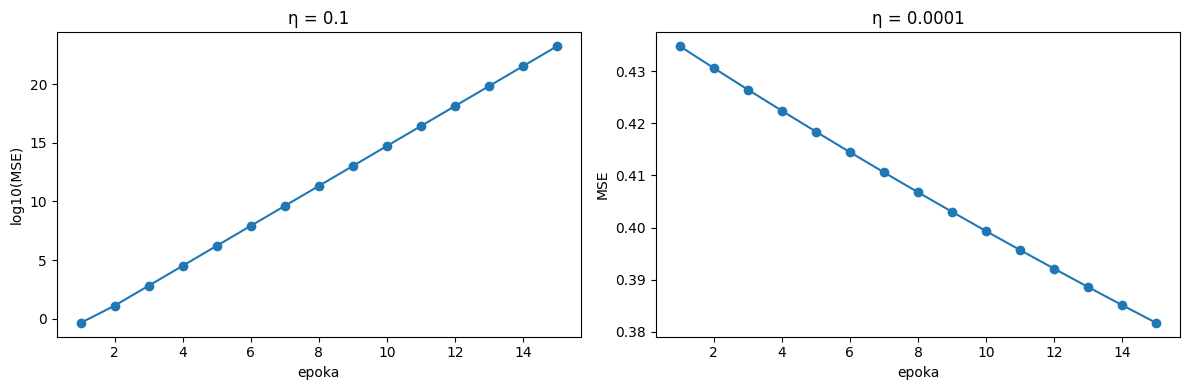

η = 0.1:    MSE w epokach 1, 2, 3: [  0.43  12.99 648.81]  ... w 15.: 1.7e+23
η = 0.0001: MSE w 1. i 15. epoce:  0.435 0.382
trafność:  η = 0.1: 0.5   η = 0.0001: 0.5


In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ada1 = AdalineGD(eta=0.1, n_iter=15).fit(X, y)
axs[0].plot(range(1, 16), np.log10(ada1.losses_), marker="o")
axs[0].set_xlabel("epoka"); axs[0].set_ylabel("log10(MSE)"); axs[0].set_title("η = 0.1")

ada2 = AdalineGD(eta=0.0001, n_iter=15).fit(X, y)
axs[1].plot(range(1, 16), ada2.losses_, marker="o")
axs[1].set_xlabel("epoka"); axs[1].set_ylabel("MSE"); axs[1].set_title("η = 0.0001")

plt.tight_layout(); plt.show()
print("η = 0.1:    MSE w epokach 1, 2, 3:", np.round(ada1.losses_[:3], 2), " ... w 15.:", f"{ada1.losses_[-1]:.1e}")
print("η = 0.0001: MSE w 1. i 15. epoce: ", round(ada2.losses_[0], 3), round(ada2.losses_[-1], 3))
print("trafność:  η = 0.1:", (ada1.predict(X) == y).mean(), "  η = 0.0001:", (ada2.predict(X) == y).mean())

Uwaga: lewy wykres ma oś pionową w skali logarytmicznej ($\log_{10}$). Wartość 20 oznacza stratę rzędu $10^{20}$.

**Pytanie 4.** Co się stało w obu przypadkach? Który przypadek z kartki 1 ($\eta = 0.25$, $1$, $1.1$) przypomina każdy z wykresów? Dlaczego oba modele mają trafność tylko 50%?

✍️ **Twoja odpowiedź:**

   * Dla $\eta = 0.1$ nastąpiła całkowita rozbieżność. Strata MSE urosła do gigantycznej wartości $1.7 \cdot 10^{23}$. Krok był zbyt duży, przez co model ciągle „przestrzeliwał” minimum, oddalając się od niego coraz bardziej.
   * Dla $\eta = 0.0001$ następuje stabilna, lecz bardzo powolna zbieżność. Strata maleje bardzo powoli, co zgadza się z moją predykcją.

   * Wykres dla $\eta = 0.1$ przypomina przypadek **$\eta = 1.1$** z kartki, a wykres dla $\eta = 0.0001$ przypomina przypadek **$\eta = 0.1$**.

  * Trafność w obu przypadkach wynosi tylko 50%, ponieważ przy $\eta = 0.1$ wagi eksplodowały do nieskończoności, przez co model stracił zdolność poprawnej klasyfikacji, a przy $\eta = 0.0001$ współczynnik uczenia jest tak mały, że 15 epok to zdecydowanie za mało, by wagi zdążyły zmienić się na tyle, by poprawnie rozdzielić klasy (model nie zdążył się nauczyć i wciąż zwraca domyślne predykcje).

### Zadanie 3: granica stabilności

Ucz Adaline przez **100 epok** dla $\eta \in \{0.001,\ 0.01,\ 0.02,\ 0.022,\ 0.024,\ 0.025,\ 0.026,\ 0.03\}$. Dla każdego $\eta$ wypisz MSE w pierwszej i ostatniej epoce oraz trafność. Znajdź największe $\eta$, przy którym strata jeszcze **maleje**.

(Przy dużych $\eta$ liczby mogą wyjść poza zakres `float` i NumPy wypisze ostrzeżenie o przepełnieniu — linijka `np.errstate` je wycisza.)

In [11]:
with np.errstate(over="ignore", invalid="ignore"):
    for eta in [0.001, 0.01, 0.02, 0.022, 0.024, 0.025, 0.026, 0.03]:
        # TODO: naucz AdalineGD (100 epok) i wypisz: eta, MSE w 1. i 100. epoce, trafność
        adaline = AdalineGD(eta=eta, n_iter=100).fit(X, y)
        print(eta,  ": ", adaline.losses_[0], adaline.losses_[-1], (adaline.predict(X) == y).mean())


0.001 :  0.4347694479212059 0.12019199240261091 1.0
0.01 :  0.4347694479212059 0.01442706759689601 1.0
0.02 :  0.4347694479212059 0.01243129377008634 1.0
0.022 :  0.4347694479212059 0.01241683216513714 1.0
0.024 :  0.4347694479212059 0.012412941286133088 1.0
0.025 :  0.4347694479212059 32.35640735379933 0.5
0.026 :  0.4347694479212059 112392214.82197458 0.5
0.03 :  0.4347694479212059 1.3993122130354151e+30 0.5


**Pytanie 5.** Gdzie leży granica stabilności dla tych danych? Porównaj z granicą $\eta < 1$ z punktu 1. Dlaczego tutaj jest dużo mniejsza?

✍️ **Twoja odpowiedź:** ...

Największe $\eta$, przy którym strata maleje wynosi tutaj 0.024, przy współczynniku większym o jedynie 0.001 widzimy już ogromny wzrost i spadek trafności.

W punkcie 1 pracowaliśmy na uproszczonym problemie jednowymiarowym, gdzie „cecha” wejściowa wynosiła domyślnie 1, dlatego stabilne $\eta$ mogło wynosić niemal $1.0$. Tutaj granica jest ponad 40 razy mniejsza, ponieważ aktualizacja wag w Adaline zależy od wartości cech, które w zbiorze Iris są duże i mnożą one poprawkę gradientu.
Skutkuje to tym, że nawet przy stosunkowo małym $\eta$, rzeczywisty krok aktualizacji wagi jest bardzo duży.

## 5. Mapa $\eta$ × epoki

Czy za małe $\eta$ da się nadrobić większą liczbą epok? A za duże?

### Zadanie 4
Dla $\eta \in \{0.001,\ 0.005,\ 0.01,\ 0.02,\ 0.025\}$ i liczby epok $\in \{15,\ 100,\ 1000\}$ naucz Adaline i zapisz MSE w ostatniej epoce oraz trafność. Wypisz wyniki jako tabelę: wiersze to $\eta$, kolumny to liczba epok.

**Przewiduję:** czy $\eta = 0.001$ po 1000 epokach dogoni $\eta = 0.01$ po 100 epokach?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):**

Wydaje mi się, że wyniki mogą być bardzo zbliżone, bo współczynnik jest 10 razy mniejszy, lecz liczba epok jest za to 10 razy większa.

In [12]:
etas = [0.001, 0.005, 0.01, 0.02, 0.025]
epoki = [15, 100, 1000]

print("η        " + "".join(f"{n:>22} epok" for n in epoki))
with np.errstate(over="ignore", invalid="ignore"):
    for eta in etas:
        wiersz = f"{eta:<8} "
        for n in epoki:
            # TODO: naucz AdalineGD(eta=eta, n_iter=n) i dopisz do wiersza MSE i trafność,
            #       np. wiersz += f"{mse:>14.3g} / {traf:.0%}"
            adaline = AdalineGD(eta=eta, n_iter=n).fit(X, y)
            traf = (adaline.predict(X) == y).mean()
            wiersz += f"{adaline.losses_[-1]:>14.3g} / {traf:.0%}"
        print(wiersz)

η                            15 epok                   100 epok                  1000 epok
0.001             0.193 / 74%          0.12 / 100%        0.0144 / 100%
0.005             0.135 / 100%         0.031 / 100%        0.0124 / 100%
0.01              0.102 / 100%        0.0144 / 100%        0.0124 / 100%
0.02             0.0596 / 100%        0.0124 / 100%        0.0123 / 100%
0.025             0.553 / 50%          32.4 / 50%       4.2e+20 / 50%


Zobaczmy to samo na wykresie: krzywe strat dla wszystkich $\eta$ przez 1000 epok (oś pozioma w skali logarytmicznej, żeby było widać i początek, i koniec).

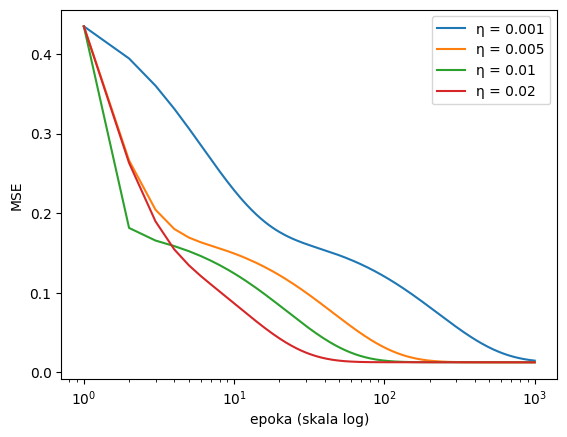

In [13]:
with np.errstate(over="ignore", invalid="ignore"):
    for eta in [0.001, 0.005, 0.01, 0.02]:
        a = AdalineGD(eta=eta, n_iter=1000).fit(X, y)
        plt.plot(range(1, 1001), a.losses_, label=f"η = {eta}")
plt.xscale("log"); plt.xlabel("epoka (skala log)"); plt.ylabel("MSE")
plt.legend(); plt.show()

**Pytanie 6.** Odpowiedz na podstawie tabeli i wykresu:
1. Ile epok potrzebuje $\eta = 0.001$, żeby dojść tam, gdzie $\eta = 0.01$ dochodzi po 100 epokach? Co z tego wynika?
2. Czy strata może spaść do zera? Co się dzieje, gdy dojdzie do „dna”?
3. Czy więcej epok pomaga przy $\eta = 0.025$?
4. Trafność 100% pojawia się dużo wcześniej niż „dno” straty. Co to znaczy?

✍️ **Twoja odpowiedź:**

1. $η = 0.001$ potrzebuje aż 1000 epok. Wynika z tego, że mniejszy współczynnik uczenia można bezpośrednio skompensować dłuższą pracą algorytmu.

2. Jak widzimy strata jest bardzo bliska zera (np. ok. 0.0123), lecz nawet po 1000 epok nie osiąga 0, a po osiągnięciu tego minimum wynik jest już stały (dobrze widać to na wykresie). Wynika to z faktu, że idealne dopasowanie matematyczne jest niemożliwe dla funkcji liniowej na tych danych.

3. Nie, trafność cały czas pozostaje taka sama (50%). Więcej epok przy zbyt dużym $\eta = 0.025$ nie tylko nie pomaga, ale drastycznie pogarsza sytuację – błąd rośnie wykładniczo z każdą kolejną epoką z powodu rozbieżności algorytmu.

4. Strata jest wówczas na tyle mała, że nie ma ona już wpływu na obniżenie trafności. Trafność 100% oznacza jedynie, że wszystkie punkty leżą po poprawnej stronie granicy decyzyjnej. Strata MSE uczy model dalej, dążąc do optymalizacji marginesu – odsuwa granicę decyzyjną od punktów tak, by leżała jak najbardziej pośrodku między klasami, co poprawia pewność predykcji.

## 6. Granica decyzyjna w czasie

Przy $\eta = 0.01$ trafność 100% pojawia się już po kilku epokach. Czy wtedy uczenie się kończy?

Granica decyzyjna Adaline to prosta $z = 0.5$, czyli $w_1 x_1 + w_2 x_2 + b = 0.5$, więc

$$x_2 = \frac{0.5 - b - w_1 x_1}{w_2}.$$

Dla porównania mamy też perceptron z poprzednich zajęć (kod poniżej jest gotowy, uruchom go).

In [14]:
class Perceptron:
    # Perceptron z poprzednich zajęć (etykiety 0/1, granica z = 0)
    def __init__(self, eta=0.1, n_iter=10, random_state=1):
        self.eta, self.n_iter, self.random_state = eta, n_iter, random_state

    def fit(self, X, y):
        rgen = np.random.RandomState(self.random_state)
        self.w_ = rgen.normal(loc=0.0, scale=0.01, size=X.shape[1])
        self.b_ = 0.0
        for _ in range(self.n_iter):
            for xi, target in zip(X, y):
                update = self.eta * (target - self.predict(xi))
                self.w_ += update * xi
                self.b_ += update
        return self

    def predict(self, X):
        return np.where(np.dot(X, self.w_) + self.b_ >= 0.0, 1, 0)

ppn = Perceptron(eta=0.1, n_iter=10).fit(X, y)
print("perceptron: w =", ppn.w_, " b =", ppn.b_, " trafność:", (ppn.predict(X) == y).mean())

perceptron: w = [-0.3538  0.9139]  b = -0.2  trafność: 1.0


### Zadanie 5
Narysuj na jednym wykresie punkty Iris oraz granice decyzyjne Adaline ($\eta = 0.01$) po $1, 5, 20, 100$ i $1000$ epokach. Dla każdej liczby epok wypisz też wagi, bias i trafność. Dorysuj granicę perceptronu (linia przerywana; dla perceptronu granica to $z = 0$, czyli $x_2 = -(b + w_1 x_1)/w_2$).

Adaline    1 epok: w = [0.0678 0.0324], b = 0.0086, trafność = 95.00%
Adaline    4 epok: w = [0.0693 0.0612], b = 0.0070, trafność = 99.00%
Adaline    5 epok: w = [0.0658 0.0681], b = 0.0058, trafność = 100.00%
Adaline   20 epok: w = [0.0202 0.1545], b = -0.0098, trafność = 100.00%
Adaline  100 epok: w = [-0.0754  0.3356], b = -0.0411, trafność = 100.00%
Adaline 1000 epok: w = [-0.0994  0.3735], b = -0.0262, trafność = 100.00%
Perceptron:      w = [-0.3538  0.9139], b = -0.2000, trafność = 100.00%


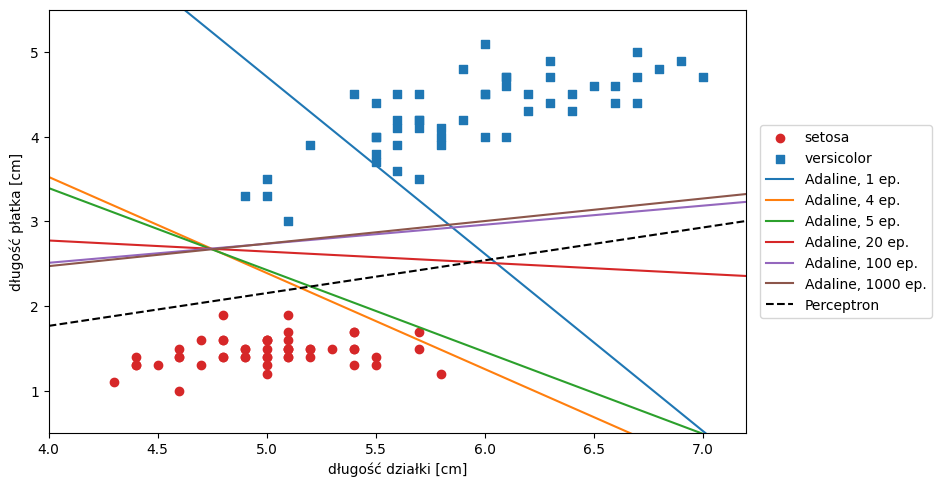

In [15]:
x1 = np.linspace(4.0, 7.2, 2)
plt.figure(figsize=(9, 5.5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:red", marker="o", label="setosa")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:blue", marker="s", label="versicolor")

for n in [1, 4, 5, 20, 100, 1000]:
    adaline = AdalineGD(eta=0.01, n_iter=n).fit(X, y)
    print(f"Adaline {n:4} epok: w = {adaline.w_}, b = {adaline.b_:.4f}, trafność = {(adaline.predict(X) == y).mean():.2%}")

    w1, w2 = adaline.w_
    b = adaline.b_
    x2 = (0.5 - b - w1 * x1) / w2
    plt.plot(x1, x2, label=f"Adaline, {n} ep.")

ppn = Perceptron(eta=0.1, n_iter=10).fit(X, y)
print(f"Perceptron:      w = {ppn.w_}, b = {ppn.b_:.4f}, trafność = {(ppn.predict(X) == y).mean():.2%}")

w1_p, w2_p = ppn.w_
b_p = ppn.b_
x2_p = -(b_p + w1_p * x1) / w2_p
plt.plot(x1, x2_p, "k--", label="Perceptron")

plt.xlim(4.0, 7.2); plt.ylim(0.5, 5.5)
plt.xlabel("długość działki [cm]"); plt.ylabel("długość płatka [cm]")
plt.legend(loc="center left", bbox_to_anchor=(1.01, 0.5)); plt.show()

**Pytanie 7.** Od której epoki trafność wynosi 100%? Co dzieje się z prostą później i dlaczego? Czym różni się położenie końcowej granicy Adaline od granicy perceptronu i skąd ta różnica?

✍️ **Twoja odpowiedź:**

* Trafność wynosi 100% od epoki 5, przy epoce 4. jest to 99%. Po kolejnych epokach prosta prawidłowo oddziela klasy, lecz można powiedzieć że coraz lepiej umiejscawia się pośrodku nich, a nie bliżej jednej z nich.

* Prosta przesuwa się później, ponieważ Adaline minimalizuje ciągłą funkcję straty (MSE). Nawet po osiągnięciu 100% trafności, rzeczywiste wartości wyjściowe $z$ różnią się od etykiet docelowych $y \in \{0, 1\}$. Model dalej modyfikuje wagi, aby zmniejszyć te różnice (czyli przybliżyć wyjścia $z$ jak najbliżej wartości 0 i 1).

* Perceptron kończy naukę (przestaje zmieniać wagi) w momencie, gdy poprawnie zaklasyfikuje wszystkie punkty (błąd dyskretny wynosi 0). Dlatego jego granica często leży przypadkowo i bardzo blisko niektórych punktów danej klasy.

* Adaline dąży do minimalizacji kwadratu błędu dla wszystkich punktów jednocześnie. Dzięki temu jej ostateczna granica decyzyjna jest stabilniejsza i przechodzi optymalnie przez środek wolnej przestrzeni dzielącej obie klasy.

## 7. Podsumowanie

Odpowiedz krótko własnymi słowami (kliknij dwukrotnie, żeby edytować):

1. Czym różni się błąd w Adaline od błędu w perceptronie?
* W perceptronie błąd liczony jest po funkcji skokowej (ma tylko wartości 0, -1, 1), a w Adaline przed funkcją skokową – na rzeczywistej wartości pobudzenia $z$, więc wiemy dokładnie, jak bardzo model się pomylił.

2. Co to jest funkcja straty i co znaczy „uczenie” w Adaline?
* Funkcja straty (MSE) określa ogólny błąd kwadratowy na całym zbiorze danych. Uczenie to szukanie takich wag i biasu za pomocą spadku gradientu, aby ta strata była jak najmniejsza.

3. Dlaczego w Adaline $\eta$ ma duże znaczenie, a w perceptronie (przy starcie od zera) nie miało?
* W Adaline błąd obliczamy na ciągłych wartościach przed funkcją skokową. Bez ograniczenia progiem zbyt duże $\eta$ powoduje, że wagi rosną w nieskończoność i błąd natychmiast eksploduje, a w perceptronie $\eta$ jedynie skalowało końcowe wagi bez zmiany kierunku prostej.

4. Czy za małe $\eta$ można nadrobić liczbą epok? A za duże?
* Za małe $\eta$ można nadrobić większą liczbą epok. Za dużego $\eta$ nie da się nadrobić, ponieważ błąd zaczyna rosnąć wykładniczo i model się rozbiega.

5. Dlaczego granica decyzyjna Adaline przesuwa się dalej, chociaż trafność jest już 100%?
* Ponieważ Adaline minimalizuje ciągłą funkcję straty (MSE). Nawet gdy się nie myli (100% trafności), dąży do tego, by punkty były jak najbliżej wartości docelowych, co odsuwa granicę decyzyjną na bezpieczny środek pomiędzy klasami.

---
## Zadanie dodatkowe (na ocenę 4/5)

Wróć do dwóch problemów, na których poległ perceptron (bez standaryzacji):

1. **versicolor vs virginica** (kwiaty 50–149, cechy 0 i 2, klasa 1 = virginica). Naucz Adaline dla $\eta \in \{0.001,\ 0.01,\ 0.02\}$ przez 1000 epok. Narysuj straty i regiony decyzyjne dla najlepszego $\eta$, policz trafność. Czy uczenie się stabilizuje? Porównaj z zachowaniem perceptronu. Czy granica stabilności jest taka sama jak dla setosa/versicolor?
2. **XOR** (4 punkty, etykiety $0, 1, 1, 0$). Naucz Adaline ($\eta = 0.1$, 500 epok, `w_init="zeros"`). Wypisz końcowe wagi, bias i $z$ dla czterech punktów. Co „wymyślił” model i dlaczego?

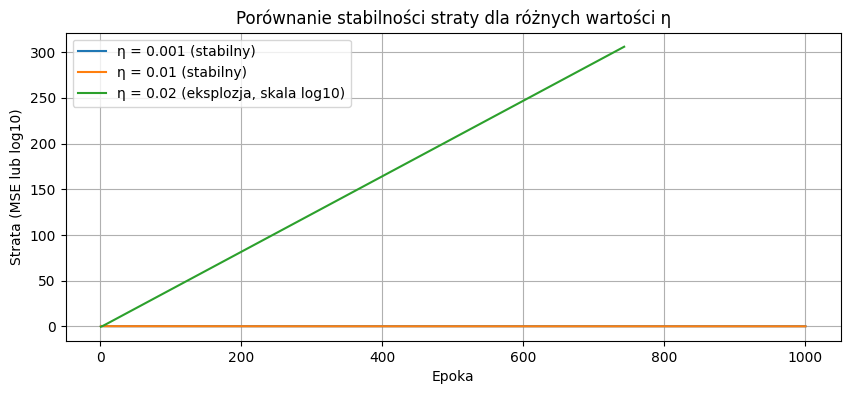

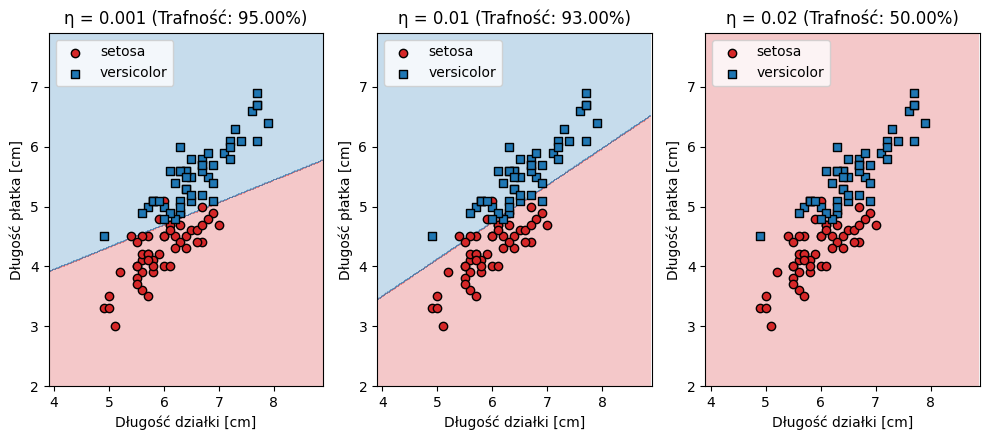

In [16]:

iris = load_iris()
X = iris.data[50:150][:, [0, 2]]
y = (iris.target[50:150] == 2).astype(int)

etas = [0.001, 0.01, 0.02]

plt.figure(figsize=(10, 4))
with np.errstate(over="ignore", invalid="ignore"):
    for e in etas:
        adel = AdalineGD(eta=e, n_iter=1000).fit(X, y)

        if not np.isnan(adel.losses_[-1]) and not np.isinf(adel.losses_[-1]) and adel.losses_[-1] < 1e5:
            plt.plot(range(1, 1001), adel.losses_, label=f"η = {e} (stabilny)")
        else:
            plt.plot(range(1, 1001), np.log10(adel.losses_), label=f"η = {e} (eksplozja, skala log10)")

plt.xlabel("Epoka")
plt.ylabel("Strata (MSE lub log10)")
plt.title("Porównanie stabilności straty dla różnych wartości η")
plt.legend()
plt.grid(True)
plt.show()


fig, axs = plt.subplots(1, 3, figsize=(10, 4.5))

with np.errstate(over="ignore", invalid="ignore"):
  adel_1 = AdalineGD(eta=0.001, n_iter=1000).fit(X, y)
  plot_decision_regions(X, y, adel_1, ax=axs[0])
  accuracy_1 = (adel_1.predict(X) == y).mean()
  axs[0].set_title(f"η = 0.001 (Trafność: {accuracy_1:.2%})")
  axs[0].set_xlabel("Długość działki [cm]")
  axs[0].set_ylabel("Długość płatka [cm]")

  adel_2 = AdalineGD(eta=0.01, n_iter=1000).fit(X, y)
  plot_decision_regions(X, y, adel_2, ax=axs[1])
  accuracy_2 = (adel_2.predict(X) == y).mean()
  axs[1].set_title(f"η = 0.01 (Trafność: {accuracy_2:.2%})")
  axs[1].set_xlabel("Długość działki [cm]")
  axs[1].set_ylabel("Długość płatka [cm]")

  adel_3 = AdalineGD(eta=0.02, n_iter=1000).fit(X, y)
  plot_decision_regions(X, y, adel_3, ax=axs[2])
  accuracy_3 = (adel_3.predict(X) == y).mean()
  axs[2].set_title(f"η = 0.02 (Trafność: {accuracy_3:.2%})")
  axs[2].set_xlabel("Długość działki [cm]")
  axs[2].set_ylabel("Długość płatka [cm]")


plt.tight_layout()
plt.show()

In [17]:
X_log = np.array([[0,0], [1, 0], [0, 1],[1,1]])
y_xor = np.array([0, 1, 1, 0])

eta = 0.1
epochs = 500

adel_xor = AdalineGD(eta=eta, n_iter=epochs, w_init="zeros").fit(X_log, y_xor)

print("Wagi:", adel_xor.w_)
print("Bias:", adel_xor.b_)
print("Loss:", adel_xor.losses_[-1])

Wagi: [0. 0.]
Bias: 0.4999999754379278
Loss: 0.2500000000000002


## Odpowiedzi na pytania:

* **1.** Na wykresie widać, że granica stabilności dla tych danych jest niższa niż dla pary setosa/versicolor. Przy $\eta = 0.02$ nastąpiła eksplozja błędu, podczas gdy dla setosa/versicolor $\eta = 0.02$ było w pełni stabilne i dawało $100\%$ trafności.

  Dzieje się tak, ponieważ klasy versicolor i virginica nakładają się na siebie i nie są liniowo separowalne, a wartości cech (długość płatka) dla virginica są większe, co zwiększa normę wektora wejściowego i silniej destabilizuje spadek gradientu.

  Perceptron na tych nieliniowo separowalnych klasach wpadał w nieskończoną pętlę i nieustannie oscylował, przez co uczenie nigdy się nie kończyło. Adaline natomiast przy odpowiednim $\eta$ stabilizuje się, minimalizując błąd średniokwadratowy (MSE) i znajdując najlepszą możliwą liniową granicę.

* **2.** Problem XOR jest liniowo nieseparowalny, więc idealne rozdzielenie klas prostą jest niemożliwe, co pokazaliśmy przy okazji badania perceptronu.

  Ponieważ rozkład punktów dla XOR jest całkowicie symetryczny, Adaline „zrezygnowało” ze zmiany wag i ustawiło je na równe zero ($w_1 = 0, w_2 = 0$). Przy zerowych wagach jedynym parametrem decyzyjnym pozostał bias ($b$).

  Model zoptymalizował go do wartości dokładnie **$0.5$** – czyli idealnego środka między klasami $0$ i $1$. Dla każdego punktu Adaline zwraca więc pobudzenie $z = 0.5$. Daje to stały błąd kwadratowy równy $0.25$ dla każdego z czterech przypadków, co jest matematycznie najlepszym (najmniej błędnym) kompromisem, jaki może osiągnąć pojedynczy neuron.